# 4. Multiple Linear Regression

## Introduction

In this notebook, we will develop and compare multiple regression models to understand how advertising channels collectively relate to Sales and whether interaction effects or nonlinear relationships improve predictive performance.

## Objectives

- Build a full additive regression model using all three advertising channels.
- Evaluate a reduced model using TV and Radio.
- Investigate interaction effects between TV and Radio advertising.
- Explore a nonlinear relationship between TV advertising and Sales.
- Compare model performance using 5-fold cross-validation.
- Examine predicted values and residual patterns to assess model fit.

## Business Questions

1. Does combining advertising channels improve Sales prediction?
2. Does Newspaper provide additional predictive value after accounting for TV and Radio?
3. Does the interaction between TV and Radio improve model performance?
4. Does modeling a nonlinear TV relationship improve predictive accuracy?

## Modeling Approach

Four regression models will be compared:

| Model | Description |
|---|---|
| Model A | Full Additive Regression |
| Model B | Reduced Additive Regression |
| Model C | Linear Interaction Model |
| Model D | Nonlinear TV + Interaction Model |

All model comparisons will use the training dataset (160 observations) and 5-fold cross-validation. The test dataset will remain untouched until final model evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_and_split, eval_regression

sns.set_theme(style="whitegrid")

df_train, df_test = load_and_split(
    path=PROJECT_ROOT / "Dataset" / "Advertising.csv"
)

df = df_train.copy()

print("Training data shape:", df_train.shape)
print("Testing data shape:", df_test.shape)

Training data shape: (160, 4)
Testing data shape: (40, 4)


## 1. Full Additive Regression Model

### Objective

Build a Multiple Linear Regression model using TV, Radio, and Newspaper advertising expenditure as predictors of Sales.

### Model Equation

Sales = β₀ + β₁(TV) + β₂(Radio) + β₃(Newspaper) + ε

### Interpretation

- β₀ represents the predicted Sales when all advertising expenditures are zero.
- β₁ represents the association between TV advertising and Sales, holding other channels constant.
- β₂ represents the association between Radio advertising and Sales, holding other channels constant.
- β₃ represents the association between Newspaper advertising and Sales, holding other channels constant.

### Statistical Evaluation

The OLS summary will be examined to understand:

- R-squared and Adjusted R-squared.
- Regression coefficients.
- P-values and statistical significance.
- AIC and BIC.

**Key question:** Does Newspaper remain statistically significant after accounting for TV and Radio advertising?

In [2]:
# baseline full additive model

model_a = smf.ols(
    "sales ~ tv + radio + newspaper",
    data=df_train
).fit()

print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     446.6
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           2.53e-76
Time:                        13:28:42   Log-Likelihood:                -306.64
No. Observations:                 160   AIC:                             621.3
Df Residuals:                     156   BIC:                             633.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9791      0.354      8.427      0.0

### Model A — Key Findings

1. The full additive model achieved an R-squared of 0.896 and an Adjusted R-squared of 0.894, indicating that the three advertising channels collectively explain approximately 89.6% of the variation in Sales.

2. TV and Radio are statistically significant predictors, with p-values below 0.05.

3. Newspaper is statistically insignificant (p-value = 0.696) after accounting for TV and Radio.

4. Compared with the individual regression models in Notebook 3, the results suggest that Newspaper provides limited additional explanatory information when the other advertising channels are included.

### Conclusion

The full additive model demonstrates strong explanatory performance. However, Newspaper does not appear to contribute meaningful independent predictive information.

Therefore, a reduced model using TV and Radio will be evaluated to determine whether removing Newspaper maintains or improves predictive performance while simplifying the model.

In [3]:
# Model ladder comparison using 5-Fold CV

## prepare the cross_validation strategy

cv=KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring={"r2":"r2",
         "rmse":"neg_root_mean_squared_error"
         }

In [4]:
## define feature transformations

from sklearn.base import BaseEstimator, TransformerMixin

class AdvertisingFeatures(BaseEstimator, TransformerMixin):

    def __init__(self, nonlinear_tv=False):
        self.nonlinear_tv = nonlinear_tv

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)

        self.tv_mean_ = (
            np.sqrt(X[:, 0]).mean()
            if self.nonlinear_tv
            else X[:, 0].mean()
        )

        self.radio_mean_ = X[:, 1].mean()

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)

        tv = (
            np.sqrt(X[:, 0])
            if self.nonlinear_tv
            else X[:, 0]
        )

        radio = X[:, 1]

        tv_c = tv - self.tv_mean_
        radio_c = radio - self.radio_mean_

        return np.column_stack([
            tv_c,
            radio_c,
            tv_c * radio_c
        ])


In [5]:
## define the 4 models

models = {

    "Model A - Full Additive": Pipeline([
        ("model", LinearRegression())
    ]),

    "Model B - Reduced Additive": Pipeline([
        ("model", LinearRegression())
    ]),

    "Model C - Linear Interaction": Pipeline([
        ("features", AdvertisingFeatures(nonlinear_tv=False)),
        ("model", LinearRegression())
    ]),

    "Model D - Nonlinear Interaction": Pipeline([
        ("features", AdvertisingFeatures(nonlinear_tv=True)),
        ("model", LinearRegression())
    ])
}

In [6]:
## prepare model inputs

X_a = df_train[["tv", "radio", "newspaper"]]
X_b = df_train[["tv", "radio"]]

y_train = df_train["sales"]

X_c = df_train[["tv", "radio"]]
X_d = df_train[["tv", "radio"]]

model_inputs = {
    "Model A - Full Additive": X_a,
    "Model B - Reduced Additive": X_b,
    "Model C - Linear Interaction": X_c,
    "Model D - Nonlinear Interaction": X_d
}

## 2. Model Comparison Using 5-Fold Cross-Validation

To identify a suitable regression model, four model specifications will be compared using 5-fold cross-validation on the training dataset.

### Model A — Full Additive Model

Includes TV, Radio, and Newspaper advertising expenditure.

### Model B — Reduced Additive Model

Includes only TV and Radio advertising expenditure.

This model evaluates whether Newspaper contributes meaningful additional predictive information.

### Model C — Linear Interaction Model

Includes centered TV and Radio variables along with their interaction term.

The interaction term helps investigate whether the relationship between TV advertising and Sales changes depending on Radio advertising expenditure.

**Model specification:**

Sales = β₀ + β₁(TV_c) + β₂(Radio_c) + β₃(TV_c × Radio_c) + ε

Here, TV_c and Radio_c represent mean-centered variables.

### Model D — Nonlinear TV + Interaction Model

Uses the square-root transformation of TV advertising expenditure, centered Radio expenditure, and their interaction.

This model investigates whether the relationship between TV advertising and Sales follows a nonlinear pattern.

**Model specification:**

Sales = β₀ + β₁(√TV_c) + β₂(Radio_c) + β₃(√TV_c × Radio_c) + ε

### Cross-Validation Strategy

5-fold cross-validation will be used to evaluate model performance.

The training dataset is divided into five folds. Each model is trained on four folds and validated on the remaining fold. This process is repeated five times.

### Evaluation Metrics

| Metric | Purpose |
|---|---|
| Train R² | Measures variation explained on training data |
| CV R² | Evaluates explanatory performance across validation folds |
| Train RMSE | Measures training prediction error |
| CV RMSE | Measures average validation prediction error |
| AIC | Compares model fit while penalizing complexity |
| BIC | Penalizes model complexity more strongly than AIC |

**Model selection:** Lower CV RMSE and higher CV R² generally indicate better predictive performance. AIC and BIC provide additional information about model fit and complexity.

In [7]:
## fit models and calculate metrics

ols_models = {
    "Model A - Full Additive": smf.ols(
        "sales ~ tv + radio + newspaper",
        data=df_train
    ).fit(),

    "Model B - Reduced Additive": smf.ols(
        "sales ~ tv + radio",
        data=df_train
    ).fit()
}

# Prepare centered features for full-training-set OLS summaries
df_ols = df_train.copy()

df_ols["tv_c"] = df_ols["tv"] - df_ols["tv"].mean()
df_ols["radio_c"] = df_ols["radio"] - df_ols["radio"].mean()

df_ols["sqrt_tv"] = np.sqrt(df_ols["tv"])
df_ols["sqrt_tv_c"] = (
    df_ols["sqrt_tv"] - df_ols["sqrt_tv"].mean()
)

df_ols["tv_c:radio_c"] = df_ols["tv_c"] * df_ols["radio_c"]
df_ols["sqrt_tv_c:radio_c"] = (
    df_ols["sqrt_tv_c"] * df_ols["radio_c"]
)

ols_models["Model C - Linear Interaction"] = smf.ols(
    "sales ~ tv_c * radio_c",
    data=df_ols
).fit()

ols_models["Model D - Nonlinear Interaction"] = smf.ols(
    "sales ~ sqrt_tv_c * radio_c",
    data=df_ols
).fit()


## evaluating the 4 models

results = []

for name, model in models.items():

    X = model_inputs[name]

    # Fit on the complete training set
    model.fit(X, y_train)

    y_pred = model.predict(X)

    train_metrics = eval_regression(y_train, y_pred)

    # 5-fold cross-validation
    cv_results = cross_validate(
        model,
        X,
        y_train,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Train R2": train_metrics["R2"],
        "Train RMSE": train_metrics["RMSE"],
        "CV R2": cv_results["test_r2"].mean(),
        "CV RMSE": -cv_results["test_rmse"].mean(),
        "AIC": ols_models[name].aic,
        "BIC": ols_models[name].bic
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(3))

print(ols_models["Model D - Nonlinear Interaction"].summary())

,Model,Train R2,Train RMSE,CV R2,CV RMSE,AIC,BIC
0,Model A - Full Additive,0.896,1.645,0.870,1.676,621.284,633.585
1,Model B - Reduced Additive,0.896,1.646,0.874,1.648,619.442,628.667
2,Model C - Linear Interaction,0.966,0.945,0.959,0.942,443.809,456.109
3,Model D - Nonlinear Interaction,0.992,0.450,0.990,0.474,206.744,219.045


                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.992
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                     6600.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          4.56e-164
Time:                        13:28:43   Log-Likelihood:                -99.372
No. Observations:                 160   AIC:                             206.7
Df Residuals:                     156   BIC:                             219.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            14.0561      0.03

## Model Comparison — Key Findings

The four regression models were evaluated using training metrics, 5-fold cross-validation, AIC, and BIC.

1. **Full Additive vs Reduced Additive:** Removing Newspaper resulted in slightly better cross-validation performance and lower AIC and BIC, suggesting that Newspaper provides limited additional predictive value.

2. **Linear Interaction Model:** Introducing an interaction between TV and Radio improved predictive performance considerably, increasing CV R-squared to 0.959 and reducing CV RMSE to 0.942.

3. **Nonlinear Interaction Model:** Applying a square-root transformation to TV advertising expenditure along with the TV–Radio interaction produced the strongest results, achieving a CV R-squared of 0.990 and CV RMSE of 0.474.

### Overall Observation

Model D demonstrates the strongest predictive performance among the four candidates. The improvement suggests that the relationship between TV advertising and Sales may be nonlinear and that the relationship may also depend on Radio advertising expenditure.

However, the model will be examined further using residual diagnostics and statistical testing before selecting it for final evaluation.

## 3. Visual Comparison of Regression Models

The Reduced Additive Model, Linear Interaction Model, and Nonlinear Interaction Model will be compared visually.

Two diagnostic plots will be used.

### 1. Predicted vs Actual Sales

This plot compares actual Sales values against model predictions.

- Points closer to the diagonal reference line indicate more accurate predictions.
- Larger deviations indicate higher prediction errors.
- A consistent pattern away from the diagonal may indicate systematic prediction errors.

### 2. Residuals vs Predicted Sales

Residuals are calculated as:

Residual = Actual Sales − Predicted Sales

This plot helps identify patterns in prediction errors.

- Randomly scattered residuals around zero suggest that the model captures the main relationship reasonably well.
- Curved patterns may indicate an unmodeled nonlinear relationship.
- Funnel-shaped patterns may indicate non-constant error variance.
- Clusters may suggest additional structure not captured by the model.

### Objective

Determine whether adding interaction effects and a nonlinear TV transformation improves the model fit and reduces systematic residual patterns.

In [8]:
# visual comparison

## predictions and residuals

visual_models = [
    "Model B - Reduced Additive",
    "Model C - Linear Interaction",
    "Model D - Nonlinear Interaction"
]

plot_results = {}

for name in visual_models:

    model = models[name]

    X = model_inputs[name]

    y_pred = model.predict(X)

    residuals = y_train - y_pred

    plot_results[name] = {
        "predicted": y_pred,
        "residuals": residuals
    }

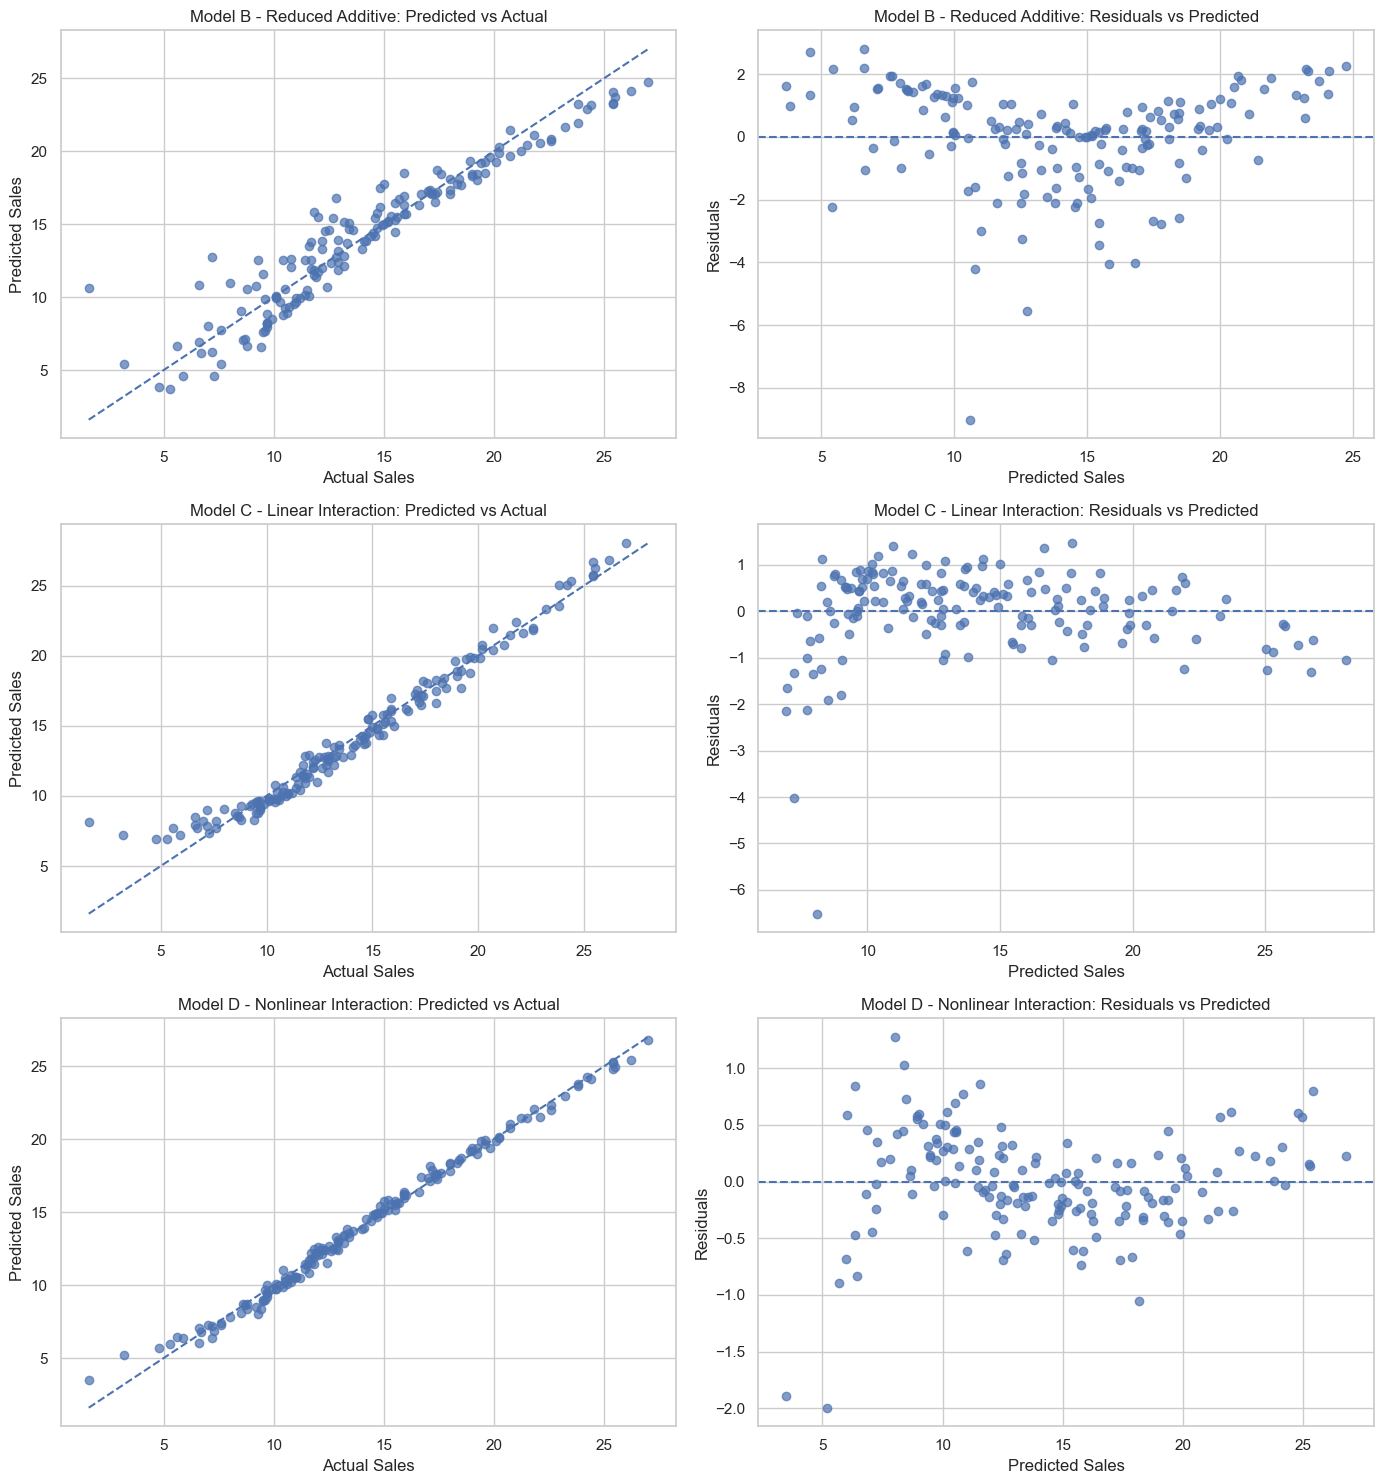

In [9]:
## Plot predicted vs actual and residuals vs predicted

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 15)
)

for i, name in enumerate(visual_models):

    y_pred = plot_results[name]["predicted"]
    residuals = plot_results[name]["residuals"]

    # Predicted vs Actual
    axes[i, 0].scatter(
        y_train,
        y_pred,
        alpha=0.7
    )

    min_val = min(y_train.min(), y_pred.min())
    max_val = max(y_train.max(), y_pred.max())

    axes[i, 0].plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--"
    )

    axes[i, 0].set_title(f"{name}: Predicted vs Actual")
    axes[i, 0].set_xlabel("Actual Sales")
    axes[i, 0].set_ylabel("Predicted Sales")

    # Residuals vs Predicted
    axes[i, 1].scatter(
        y_pred,
        residuals,
        alpha=0.7
    )

    axes[i, 1].axhline(
        y=0,
        linestyle="--"
    )

    axes[i, 1].set_title(f"{name}: Residuals vs Predicted")
    axes[i, 1].set_xlabel("Predicted Sales")
    axes[i, 1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

### Visual Comparison — Key Findings

1. **Model B (Reduced Additive):** The Predicted vs Actual plot shows noticeable spread around the diagonal line, and the Residuals vs Predicted plot displays a clear curved pattern. Errors are strongly negative at low and high predicted sales and positive in the middle, confirming that a purely additive linear model misses both the channel synergy and the curvature in TV spend.

2. **Model C (Linear Interaction):** Adding the TV and Radio interaction pulls predictions much closer to the diagonal and cuts the error spread nearly in half. However, a distinct inverted U-shaped curve remains in the residuals, showing that linear TV still overpredicts at the extremes and underpredicts in the middle.

3. **Model D (Nonlinear Interaction):** Transforming TV with a square root alongside the centered interaction aligns predictions tightly along the diagonal and flattens the residual curve almost completely around zero. Only two low-sales observations stand out with negative residuals around minus 1.5 to minus 2.2, which will be checked formally with Cook's distance in Notebook 6.

## 4. Conclusion

Across 5-fold cross-validation on the 160 training markets, **Model D (Nonlinear TV + Centered Interaction)** is the clear winner, improving CV R-squared from 0.874 in the reduced additive model to 0.990 and reducing CV RMSE from 1.648 to 0.474 while achieving the lowest AIC (206.744) and BIC (219.045).

Removing Newspaper simplified the model without losing predictive accuracy, while combining a square-root TV term with the TV-Radio interaction captured both diminishing returns on TV spend and cross-channel synergy. Model D will be carried forward to Notebook 5 for formal statistical testing (partial F-tests, VIF, and heteroskedasticity checks) and to Notebook 6 for residual diagnostics and final held-out test evaluation.